In [75]:
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta
import networkx as nx
import pandas as pd


def run_Zollman_sim(topo_type, networksize, num_rounds, num_pulls_per_round, t_p_A, t_p_B, max_prior):
    if topo_type== "Cycle":
        agent_net = nx.cycle_graph(networksize)
    elif topo_type == "Wheel":
        agent_net = nx.wheel_graph(networksize)
    else:
        agent_net = nx.complete_graph(networksize)

    for node in agent_net.nodes:
        agent_net.nodes[node]['belief'] = {
            "Theory A": {"alpha": random.uniform(0, max_prior), "beta": random.uniform(0, max_prior)},
            "Theory B": {"alpha": random.uniform(0, max_prior), "beta": random.uniform(0, max_prior)}
        }

    better = "Theory A" if t_p_A > t_p_B else "Theory B"

    for i in range(num_rounds):
        round_results = {}
        
        # Action Step
        for node in agent_net.nodes:
            
            agent_belief = agent_net.nodes[node]["belief"]

            ev_A = agent_belief["Theory A"]["alpha"] / (agent_belief["Theory A"]["alpha"] + agent_belief["Theory A"]["beta"])
            ev_B = agent_belief["Theory B"]["alpha"] / (agent_belief["Theory B"]["alpha"] + agent_belief["Theory B"]["beta"])

            if ev_A > ev_B:
                chosen_theory = "Theory A"
            elif ev_B > ev_A:
                chosen_theory = "Theory B"
            else:
                chosen_theory = random.choice(["Theory A", "Theory B"])

            if chosen_theory == "Theory A":
                successes = np.random.binomial(num_pulls_per_round, t_p_A)
                failures = num_pulls_per_round - successes
            else: 
                successes = np.random.binomial(num_pulls_per_round, t_p_B)
                failures = num_pulls_per_round - successes
            
            round_results[node] = {"theory": chosen_theory, "successes": successes, "failures": failures}
        
         # break if consensus 
        theories_chosen = []
        for r in round_results.values():
            theories_chosen.append(r["theory"])

        # set checks if all same
        if len(set(theories_chosen)) == 1:
            agreed_theory = theories_chosen[0]
            return agreed_theory == better
                
        # Updating Step
        for node in agent_net.nodes:
            agent_belief = agent_net.nodes[node]["belief"]
            observable_nodes = [node] + list(agent_net.neighbors(node))
            for o_node in observable_nodes:
                o_result = round_results[o_node]
                belief = agent_belief[o_result["theory"]]
                # we've already grabbed the beliefs in the right theory and can update directly 
                belief["alpha"] += o_result["successes"]
                belief["beta"] += o_result["failures"]


    # Evaluate once, after all rounds: does every agent prefer the better theory (A)?
    num_successes = 0
    # true of A is better, else false
    A_is_better = t_p_A > t_p_B 

    for node in agent_net.nodes:
        b = agent_net.nodes[node]["belief"]
        exp_A = b["Theory A"]["alpha"] / (b["Theory A"]["alpha"] + b["Theory A"]["beta"])
        exp_B = b["Theory B"]["alpha"] / (b["Theory B"]["alpha"] + b["Theory B"]["beta"])
        
        # condensed conditional (checks if the agents prefer the better theory)
        if (exp_A > exp_B) == A_is_better and exp_A != exp_B:
            num_successes += 1
    
    return num_successes == len(agent_net.nodes)

Processed Cycle Size 4: 54.21%
Processed Cycle Size 5: 58.36%
Processed Cycle Size 6: 63.7%
Processed Cycle Size 7: 69.17%
Processed Cycle Size 8: 74.92999999999999%
Processed Cycle Size 9: 80.25999999999999%
Processed Cycle Size 10: 82.95%
Processed Wheel Size 5: 54.39000000000001%
Processed Wheel Size 6: 56.88999999999999%
Processed Wheel Size 7: 59.18%
Processed Wheel Size 8: 61.09%
Processed Wheel Size 9: 65.25999999999999%
Processed Wheel Size 10: 66.44%
Processed Complete Size 3: 52.55%
Processed Complete Size 4: 52.66%
Processed Complete Size 5: 52.769999999999996%
Processed Complete Size 6: 53.169999999999995%
Processed Complete Size 7: 53.080000000000005%
Processed Complete Size 8: 53.12%
Processed Complete Size 9: 52.78%
Processed Complete Size 10: 54.769999999999996%
[{'Topology': 'Cycle', 'Network Size': 4, 'Truth Found (%)': 54.21}, {'Topology': 'Cycle', 'Network Size': 5, 'Truth Found (%)': 58.36}, {'Topology': 'Cycle', 'Network Size': 6, 'Truth Found (%)': 63.7}, {'Topol

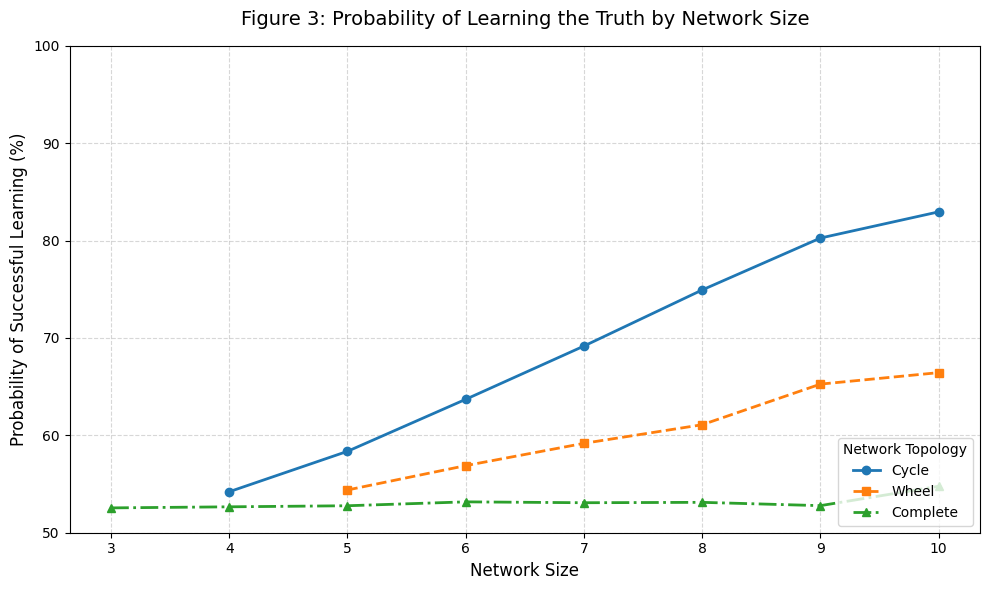

In [78]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Experimental Parameters
topologies = {
    "Cycle": range(4, 11),
    "Wheel": range(5, 11),
    "Complete": range(3, 11),
}

true_p_A = 0.5
true_p_B = 0.499

num_pulls_per_round = 1000
num_rounds = 10000
num_iterations = 10000

max_prior_bound = 4

results_data = []

for topo_type, sizes in topologies.items():
    for networksize in sizes:
        n_successes = 0
        for _ in range(num_iterations): 
            if(run_Zollman_sim(topo_type, networksize, num_rounds, num_pulls_per_round,true_p_A, true_p_B, max_prior_bound)):
                n_successes += 1
            
        win_rate = n_successes / num_iterations * 100
        print(f"Processed {topo_type} Size {networksize}: {win_rate}%")
        results_data.append({"Topology": topo_type, "Network Size": networksize, "Truth Found (%)": win_rate}) 
print(results_data)
# 3. Create DataFrame and Pivot for a Line Chart
df = pd.DataFrame(results_data)
df_pivot = df.pivot(index="Network Size", columns="Topology", values="Truth Found (%)")

# 4. Matplotlib Figure 3 Replication
plt.figure(figsize=(10, 6))

# Plotting each line with distinct markers to match academic formatting
plt.plot(df_pivot.index, df_pivot['Cycle'], marker='o', linestyle='-', linewidth=2, label='Cycle')
plt.plot(df_pivot.index, df_pivot['Wheel'], marker='s', linestyle='--', linewidth=2, label='Wheel')
plt.plot(df_pivot.index, df_pivot['Complete'], marker='^', linestyle='-.', linewidth=2, label='Complete')

plt.title("Figure 3: Probability of Learning the Truth by Network Size", fontsize=14, pad=15)
plt.xlabel("Network Size", fontsize=12)
plt.ylabel("Probability of Successful Learning (%)", fontsize=12)

# Set X-axis to show every integer step
plt.xticks(df_pivot.index)
# Standardize Y-axis so we can compare across different diagnostic charts
plt.ylim(50, 100) 

plt.legend(title="Network Topology", loc="lower right")
plt.grid(axis='both', linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()